Data Loaded Successfully!
Shape of Dataset: (614, 13)

--- DATA CLEANING ---

Missing Values in Each Column:

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

Numeric Columns: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']
Categorical Columns: ['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area', 'Loan_Status']

 Missing Values Handled.
Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0

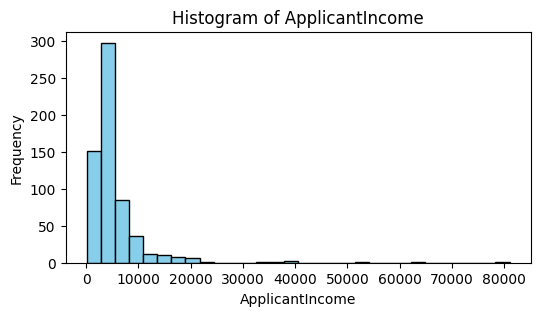

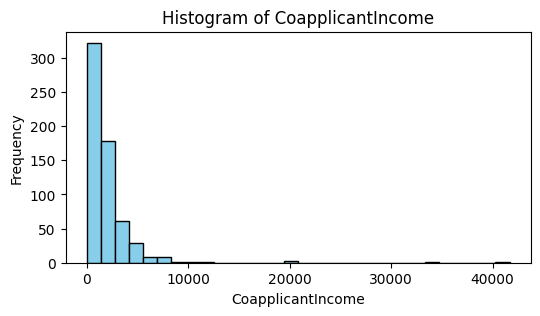

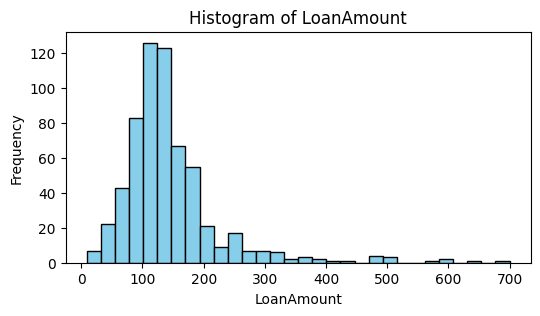

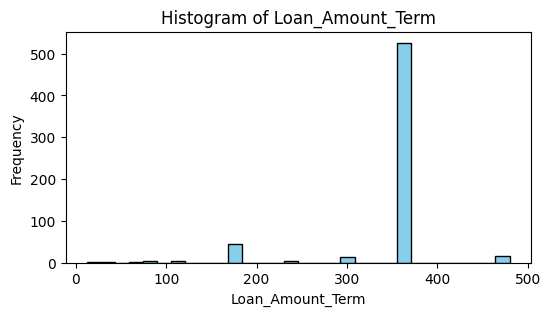

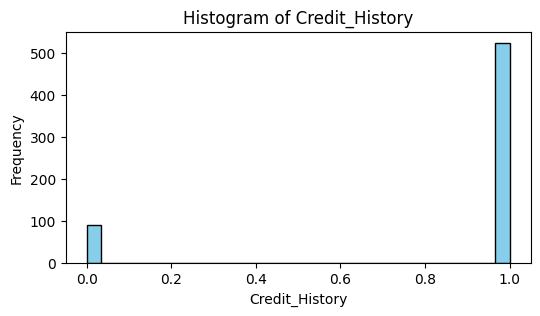

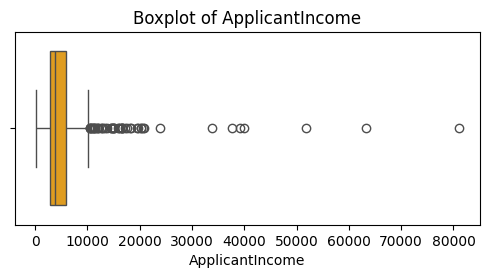

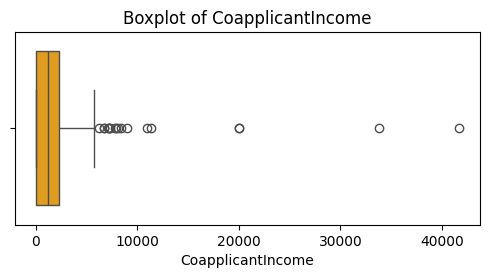

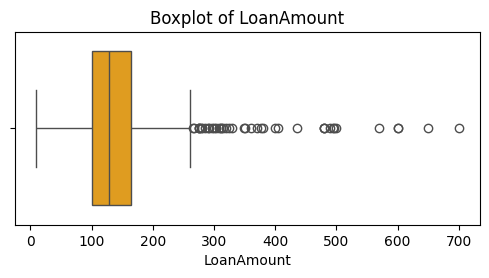

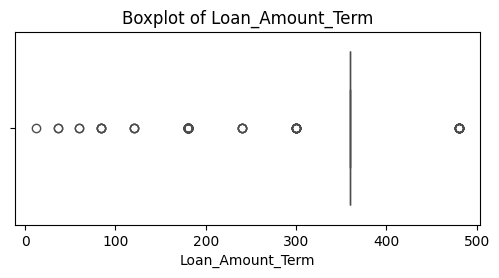

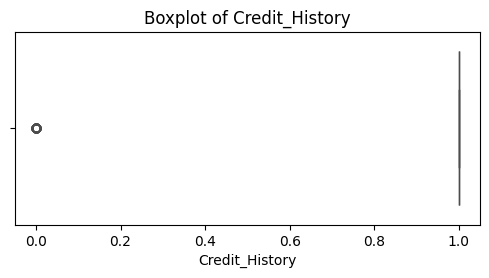

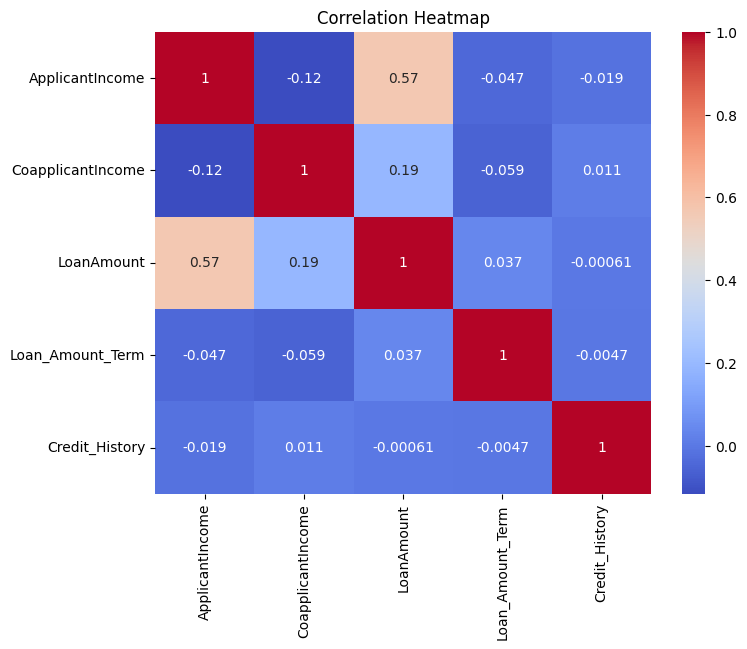

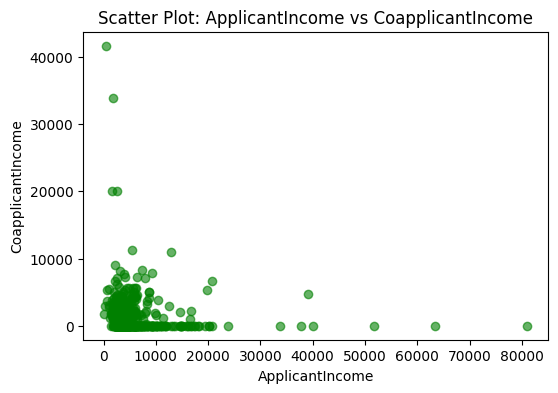


--- NORMALITY CHECK (Q-Q Plot) ---


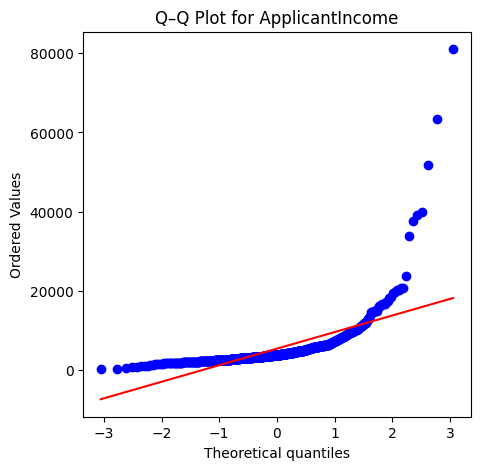


--- CONFIDENCE INTERVAL & HYPOTHESIS TEST ---

Feature Selected: ApplicantIncome
Sample Size: 614
Mean: 5403.4593, Std Dev: 6109.0417
95% Confidence Interval: (4919.2921, 5887.6264)

Hypothesis Test for mean(ApplicantIncome) = 1000
t-statistic = 17.8610, p-value = 0.000000
Reject Null Hypothesis: Mean differs significantly from the specified value.

--- SIMPLE LINEAR REGRESSION ---
Target Variable: Credit_History
Predictor Variables: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']
Coefficients: [-1.77062255e-06 -1.28872233e-06  1.40777569e-04 -1.36245829e-04]
Intercept: 0.8949

Model Performance:
MSE = 0.1315
RMSE = 0.3627
R² = -0.0071


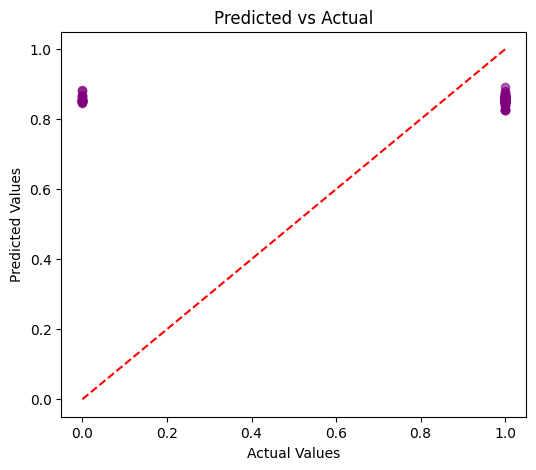

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import math
import warnings
warnings.filterwarnings('ignore')

DATA_PATH = "train.csv"
df = pd.read_csv(DATA_PATH)

print("Data Loaded Successfully!")
print("Shape of Dataset:", df.shape)
df.head()

print("\n--- DATA CLEANING ---")

print("\nMissing Values in Each Column:\n")
print(df.isnull().sum())

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

print("\nNumeric Columns:", numeric_cols)
print("Categorical Columns:", cat_cols)

for col in numeric_cols:
    if df[col].isnull().sum() > 0:
        df[col].fillna(df[col].median(), inplace=True)

for col in cat_cols:
    if df[col].isnull().sum() > 0:
        df[col].fillna(df[col].mode()[0], inplace=True)

print("\n Missing Values Handled.")
print(df.isnull().sum())

print("\n--- DESCRIPTIVE STATISTICS ---")
desc = df[numeric_cols].describe().T
desc['mode'] = df[numeric_cols].mode().iloc[0]
desc.rename(columns={'50%': 'median'}, inplace=True)
print(desc[['mean', 'median', 'mode', 'std', 'min', 'max']])

print("\nInterpretation:")
for col in numeric_cols:
    print(f"- {col}: Mean={df[col].mean():.2f}, Median={df[col].median():.2f}, Std={df[col].std():.2f}")

print("\n--- VISUALIZATION ---")

# Histograms
for col in numeric_cols:
    plt.figure(figsize=(6, 3))
    plt.hist(df[col], bins=30, color='skyblue', edgecolor='black')
    plt.title(f"Histogram of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

# Boxplots
for col in numeric_cols:
    plt.figure(figsize=(6, 2.5))
    sns.boxplot(x=df[col], color='orange')
    plt.title(f"Boxplot of {col}")
    plt.show()

# Correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

#scatterplot
if len(numeric_cols) >= 2:
    plt.figure(figsize=(6, 4))
    plt.scatter(df[numeric_cols[0]], df[numeric_cols[1]], alpha=0.6, color='green')
    plt.xlabel(numeric_cols[0])
    plt.ylabel(numeric_cols[1])
    plt.title(f"Scatter Plot: {numeric_cols[0]} vs {numeric_cols[1]}")
    plt.show()

print("\n--- NORMALITY CHECK (Q-Q Plot) ---")

selected_col = numeric_cols[0]
plt.figure(figsize=(5, 5))
stats.probplot(df[selected_col], dist="norm", plot=plt)
plt.title(f"Q–Q Plot for {selected_col}")
plt.show()


print("\n--- CONFIDENCE INTERVAL & HYPOTHESIS TEST ---")

feature = numeric_cols[0]
alpha = 0.05
specified_value = 1000

data = df[feature].dropna()
n = len(data)
mean = data.mean()
std = data.std(ddof=1)
se = std / math.sqrt(n)
t_crit = stats.t.ppf(1 - alpha/2, df=n-1)

ci_lower = mean - t_crit * se
ci_upper = mean + t_crit * se

print(f"\nFeature Selected: {feature}")
print(f"Sample Size: {n}")
print(f"Mean: {mean:.4f}, Std Dev: {std:.4f}")
print(f"95% Confidence Interval: ({ci_lower:.4f}, {ci_upper:.4f})")

t_stat, p_val = stats.ttest_1samp(data, popmean=specified_value)
print(f"\nHypothesis Test for mean({feature}) = {specified_value}")
print(f"t-statistic = {t_stat:.4f}, p-value = {p_val:.6f}")

if p_val < alpha:
    print("Reject Null Hypothesis: Mean differs significantly from the specified value.")
else:
    print("Fail to Reject Null Hypothesis: No significant difference from the specified value.")

print("\n--- SIMPLE LINEAR REGRESSION ---")


target_col = numeric_cols[-1]
predictors = numeric_cols[:-1]

X = df[predictors]
y = df[target_col]

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fit model
model = LinearRegression()
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluate model
mse = mean_squared_error(y_test, y_pred)
rmse = math.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Target Variable: {target_col}")
print(f"Predictor Variables: {predictors}")
print(f"Coefficients: {model.coef_}")
print(f"Intercept: {model.intercept_:.4f}")
print(f"\nModel Performance:")
print(f"MSE = {mse:.4f}")
print(f"RMSE = {rmse:.4f}")
print(f"R² = {r2:.4f}")

# Plot predicted vs actual
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, alpha=0.6, color='purple')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Predicted vs Actual")
plt.show()
